# Tabnet Model Training & Evaluation

In [8]:
import torch
import numpy as np
from pytorch_tabnet.tab_model import TabNetClassifier
import sys
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
sys.path.insert(0, PROJECT_ROOT)

# Import and run your pipeline code to pull the clean data splits
from src.pipeline import get_data

print("Fetching pipeline data splits...")
data = get_data()

# Pull the continuous dense matrices and targets that your neural network requires
X_train = data["X_train_dense"]
y_train = data["y_train"]

X_val = data["X_val_dense"]
y_val = data["y_val"]

X_test = data["X_test_dense"]
y_test = data["y_test"]

# Detect if a graphics card GPU is available to speed up training
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using active hardware device: {device}")

# 1. Calculate the standard class balance weights inverse ratio
class_counts = np.bincount(y_train)
total_samples = len(y_train)

weight_class_0 = total_samples / (2.0 * class_counts[0])
weight_class_1 = total_samples / (2.0 * class_counts[1])

# FIXED: Push the weight tensor directly to the active hardware device (.to(device))
ce_weights_tensor = torch.tensor([weight_class_0, weight_class_1], dtype=torch.float32).to(device)
print(f"CrossEntropy weights configured: Legitimate={weight_class_0:.4f}, Fraud={weight_class_1:.4f}")

# Define the loss function structure that matches TabNet's multi-column output shape
custom_loss_fn = torch.nn.CrossEntropyLoss(weight=ce_weights_tensor)

# Initialize the TabNet Classifier cleanly
model = TabNetClassifier(
    n_d=16, n_a=16,                
    n_steps=5,                     
    gamma=1.5,                     
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2, weight_decay=1e-5), 
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    scheduler_params=dict(step_size=5, gamma=0.5),
    mask_type='sparsemax',
    verbose=1,
    seed=42,
    device_name=device             # Forces the network initialization onto your GPU device
)

# Train the model using the custom loss function
print("Training TabNet Neural Network...")
model.fit(
    X_train=X_train, y_train=y_train,
    eval_set=[(X_val, y_val)],
    eval_name=['valid'],
    eval_metric=['auc'],           
    max_epochs=40,                 
    patience=10,                   
    batch_size=4096,               
    virtual_batch_size=256,        
    num_workers=0,
    drop_last=False,
    loss_fn=custom_loss_fn,        
    weights=0                      
)

# Generate predictions safely
print("Generating test predictions...")
test_probabilities = model.predict_proba(X_test)[:, 1]


Fetching pipeline data splits...
Using active hardware device: cuda
CrossEntropy weights configured: Legitimate=0.5050, Fraud=50.1236
Training TabNet Neural Network...


c:\Users\shubh\AppData\Local\Programs\Python\Python312\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.64578 | valid_auc: 0.80691 |  0:00:38s
epoch 1  | loss: 0.53734 | valid_auc: 0.83769 |  0:01:18s
epoch 2  | loss: 0.50521 | valid_auc: 0.84313 |  0:01:58s
epoch 3  | loss: 0.47444 | valid_auc: 0.85669 |  0:02:39s
epoch 4  | loss: 0.45368 | valid_auc: 0.87172 |  0:03:19s
epoch 5  | loss: 0.44159 | valid_auc: 0.87284 |  0:03:57s
epoch 6  | loss: 0.43933 | valid_auc: 0.8748  |  0:04:37s
epoch 7  | loss: 0.43538 | valid_auc: 0.87462 |  0:05:21s
epoch 8  | loss: 0.43539 | valid_auc: 0.87559 |  0:05:59s
epoch 9  | loss: 0.43404 | valid_auc: 0.87857 |  0:06:36s
epoch 10 | loss: 0.42778 | valid_auc: 0.87966 |  0:07:15s
epoch 11 | loss: 0.42577 | valid_auc: 0.88098 |  0:07:53s
epoch 12 | loss: 0.42509 | valid_auc: 0.87934 |  0:08:33s
epoch 13 | loss: 0.42422 | valid_auc: 0.87956 |  0:09:12s
epoch 14 | loss: 0.42203 | valid_auc: 0.88168 |  0:09:51s
epoch 15 | loss: 0.41904 | valid_auc: 0.88014 |  0:10:31s
epoch 16 | loss: 0.41987 | valid_auc: 0.88104 |  0:11:09s
epoch 17 | los

c:\Users\shubh\AppData\Local\Programs\Python\Python312\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Generating test predictions...


Running complete evaluation report...
 EVALUATION REPORT: TABNET
Accuracy:                 97.9386%
Fraud precision:          24.9814%
Fraud recall:             23.3843%
Fraud F1:                 24.1565%
PR-AUC (AP):              17.3554%
ROC-AUC:                  87.9077%
Recall @ FPR <= 1.00%:    23.3843%
FPR at chosen threshold:  0.9998%
Chosen Decision Boundary: 0.9219
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99    202133
       Fraud       0.25      0.23      0.24      2878

    accuracy                           0.98    205011
   macro avg       0.62      0.61      0.62    205011
weighted avg       0.98      0.98      0.98    205011



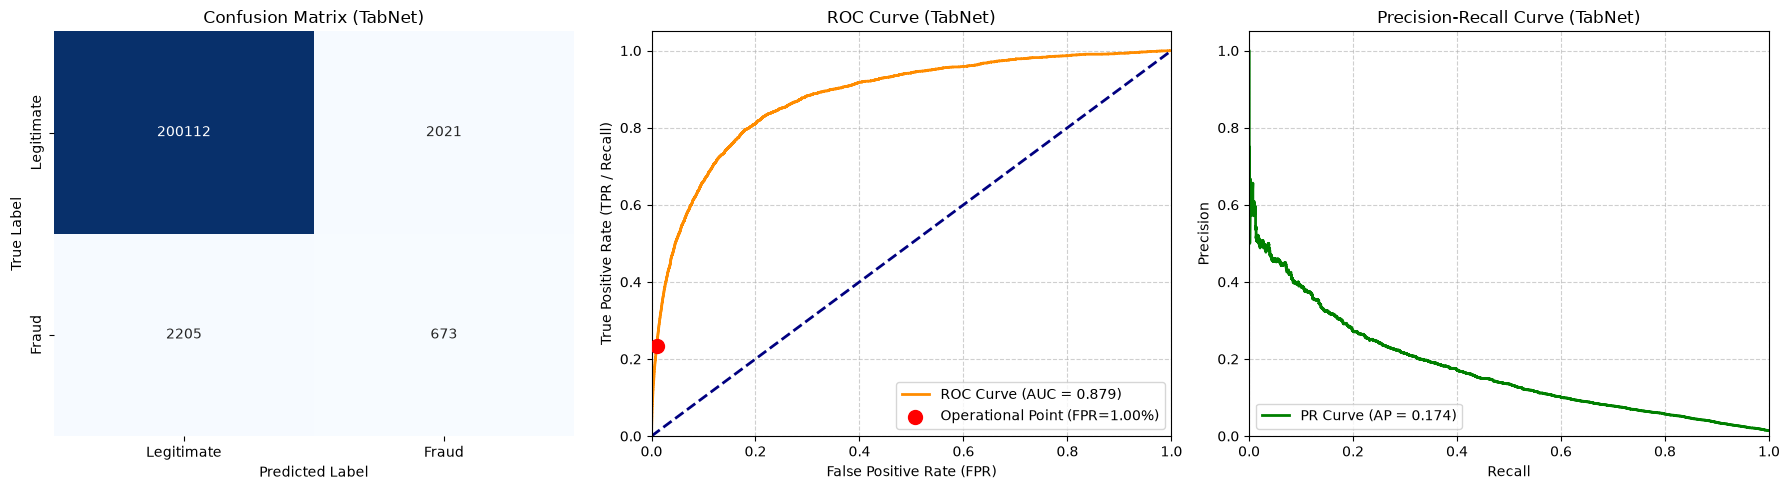

In [ ]:
# Import and run your standardized metrics evaluation script
print("Running complete evaluation report...")
from src.evaluation import evaluate_predictions
evaluate_predictions(
    y_true=y_test,
    y_probs=test_probabilities,
    model_name="TabNet"
)

In [ ]:
import os
from pathlib import Path

# Create the models directory if it doesn't exist
MODELS_DIR = Path(PROJECT_ROOT) / "models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Save the TabNet weights and network architecture
tabnet_save_prefix = MODELS_DIR / "tabnet_model"
tabnet_saved_filepath = model.save_model(str(tabnet_save_prefix))

print(f"TabNet model successfully saved to: {tabnet_saved_filepath}")


Successfully saved model at C:\Users\shubh\projects\FairFraud\models\tabnet_model.zip
TabNet model successfully saved to: C:\Users\shubh\projects\FairFraud\models\tabnet_model.zip
